# Capstone Project: 

## In what year will the world's population growth rate drop to zero, and what will the peak population be then? Also, how can altering the resource-efficiency shift that peak?

#### By - Chinar Kulkarni


![](images/combined_image.jpg)


##### Today, the world population has crossed the 8 billion mark. With the advent of medical science, travel, and improved living standards, the growth rate has risen unprecedentedly over the past century. However, there will come a time when the limits of essential resources like water, food, fuel, and shelter will outweigh the population growth potential. Some parts of the world are already facing extreme shortages of necessities. Hence, it is inevitable that population growth will continue its downward trajectory until it reaches a point when birth and death rates are identical, and world population reaches its maximum. I believe that the answers to the questions above lie hidden in the world population, GDP, and demographic data.

##### In my capstone project, I intend to utilize the World population data and the population growth data to build models that will study the growth curve so far of each country in the world, and use that knowledge to predict the population growth for the near future. This will help us answer the first question: When will the resource limits outweigh the growth potential, and will world population growth become zero? 

##### As a next step, I plan on trying to utilize the available resource data (gas, food, wood, waste) to understand what drives the growth rate down, and how we can change our resource usage and habits to shift the peak population ahead in time. 

In [1]:
# Importing all the required libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

##### Here are the datasets I have used for this project:

##### 1. World Population Analysis by Hasib Al Muzdadid (https://www.kaggle.com/code/hasibalmuzdadid/world-population-analysis/notebook)
##### 2. Population Growth by each country by Mahmoud Gamil (https://www.kaggle.com/code/mahmoudredagamail/population-growth-by-each-country-1961-2023/notebook)

In [2]:
# Importing the datasets

pop_data = pd.read_csv('data/world_population.csv')
pop_growth_data = pd.read_csv('data/API_SP.POP.GROW_DS2_en_csv_v2_2594848.csv')

##### The first dataset provided the population of each country at the beginning of each decade, starting from 1970. 

In [3]:
pop_data.head()

,Rank,CCA3,Country/Territory,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771,38972230,33753499,28189672,19542982,10694796,12486631,10752971,652230,63.0587,1.0257,0.52
1,138,ALB,Albania,Tirana,Europe,2842321,2866849,2882481,2913399,3182021,3295066,2941651,2324731,28748,98.8702,0.9957,0.04
2,34,DZA,Algeria,Algiers,Africa,44903225,43451666,39543154,35856344,30774621,25518074,18739378,13795915,2381741,18.8531,1.0164,0.56
3,213,ASM,American Samoa,Pago Pago,Oceania,44273,46189,51368,54849,58230,47818,32886,27075,199,222.4774,0.9831,0.00
4,203,AND,Andorra,Andorra la Vella,Europe,79824,77700,71746,71519,66097,53569,35611,19860,468,170.5641,1.0100,0.00



##### The second dataset provided the percent growth in population for each country every year from 1960.

In [4]:
pop_growth_data.head()

,Country Name,Country Code,1961,1962,1963,1964,1965,1966,1967,1968,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Aruba,ABW,2.179059,1.548572,1.389337,1.215721,1.032841,0.862184,0.388847,-0.085719,...,0.691615,0.637959,0.590062,0.537296,0.494795,0.451970,0.134255,-0.045045,-0.086392,-0.157953
1,Africa Eastern and Southern,AFE,2.660180,2.732633,2.753248,2.806915,2.840787,2.813609,2.830505,2.881589,...,2.774990,2.802586,2.728159,2.655672,2.688371,2.691134,2.678184,2.607472,2.543757,2.531587
2,Afghanistan,AFG,1.925952,2.014879,2.078997,2.139651,2.216007,2.253524,2.292638,2.347351,...,3.657576,3.121341,2.581549,2.866492,2.885208,2.908529,3.134747,2.851358,2.534498,2.665628
3,Africa Western and Central,AFW,2.115789,2.145723,2.190827,2.211360,2.242567,2.272816,2.275721,2.295953,...,2.750731,2.723317,2.713059,2.706266,2.669239,2.633982,2.615646,2.573377,2.539799,2.540864
4,Angola,AGO,1.558355,1.460738,1.410425,1.301745,1.111041,0.875806,0.696698,0.695985,...,3.684429,3.617678,3.586211,3.550987,3.464457,3.395278,3.268348,3.166030,3.096753,3.030996


##### Since I needed as many data points as I can collect, I merged both these datasets, and calculated the actual population each year for every country.

##### In order to correctly merge the datasets by country name, I had to first rename the 'By' column for merge. Also, some country names did not match, so I had to manually inspect the names and match them in the two datasets.

In [5]:
# Renaming the name of the field to be used for merging
pop_data = pop_data.rename(columns={'Country/Territory': 'Country Name'})

# Renaming the country names to match them between the datasets
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Bahamas, The', "Country Name"] = 'Bahamas'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Brunei Darussalam', "Country Name"] = 'Brunei'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Cabo Verde', "Country Name"] = 'Cape Verde'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Congo, Dem. Rep.', "Country Name"] = 'DR Congo'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Czechia', "Country Name"] = 'Czech Republic'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Egypt, Arab Rep.', "Country Name"] = 'Egypt'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Gambia, The', "Country Name"] = 'Gambia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Hong Kong SAR, China', "Country Name"] = 'Hong Kong'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Iran, Islamic Rep.', "Country Name"] = 'Iran'
pop_growth_data.loc[pop_growth_data['Country Name'] == "Cote d'Ivoire", "Country Name"] = 'Ivory Coast'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Lao PDR', "Country Name"] = 'Laos'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Macao SAR, China', "Country Name"] = 'Macau'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Congo, Rep.', "Country Name"] = 'Republic of the Congo'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Russian Federation', "Country Name"] = 'Russia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Sint Maarten (Dutch part)', "Country Name"] = 'Sint Maarten'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Slovak Republic', "Country Name"] = 'Slovakia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Kitts and Nevis', "Country Name"] = 'Saint Kitts and Nevis'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Lucia', "Country Name"] = 'Saint Lucia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Martin (French part)', "Country Name"] = 'Saint Martin'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'St. Vincent and the Grenadines', "Country Name"] = 'Saint Vincent and the Grenadines'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Micronesia, Fed. Sts.', "Country Name"] = 'Micronesia'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Syrian Arab Republic', "Country Name"] = 'Syria'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Turkiye', "Country Name"] = 'Turkey'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Venezuela, RB', "Country Name"] = 'Venezuela'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Viet Nam', "Country Name"] = 'Vietnam'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Virgin Islands (U.S.)', "Country Name"] = 'United States Virgin Islands'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Yemen, Rep.', "Country Name"] = 'Yemen'
pop_growth_data.loc[pop_growth_data['Country Name'] == "Korea, Dem. People's Rep.", "Country Name"] = 'North Korea'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Korea, Rep.', "Country Name"] = 'South Korea'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Kyrgyz Republic', "Country Name"] = 'Kyrgyzstan'
pop_growth_data.loc[pop_growth_data['Country Name'] == 'Czechia', "Country Name"] = 'CzechRepublic'

# Merging the two datasets
data = pd.merge(pop_data, pop_growth_data, on='Country Name', how='inner')[['Country Name','Country Code','Continent','1970 Population','1970','1971','1972','1973','1974','1975','1976','1977','1978','1979','1980','1981','1982','1983','1984','1985','1986','1987','1988','1989','1990','1991','1992','1993','1994','1995','1996','1997','1998','1999','2000','2001','2002','2003','2004','2005','2006','2007','2008','2009','2010','2011','2012','2013','2014','2015','2016','2017','2018','2019','2020','2021','2022','2023']]


##### After merging the datasets, I now calculate the population of each country for every year starting 1970, based on the percent growth every year.

In [6]:
# Calculating the population of each country every year

exclude = ['Country Name','Country Code','Continent']
prev = []
for col in [c for c in data.columns if c not in exclude]:
    if(col != '1970 Population'):
        data[col] = round(prev * (1 + (data[col] / 100)))
    prev = data[col]

data.head()

,Country Name,Country Code,Continent,1970 Population,1970,1971,1972,1973,1974,1975,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,AFG,Asia,10752971,11014610.0,11280653.0,11554705.0,11846394.0,12144095.0,12434738.0,...,31766835.0,32758386.0,33604060.0,34567318.0,35564657.0,36599065.0,37746353.0,38822637.0,39806596.0,40867692.0
1,Albania,ALB,Europe,2324731,2384031.0,2441795.0,2502717.0,2561845.0,2620696.0,2681002.0,...,3209228.0,3199883.0,3194767.0,3191829.0,3183954.0,3170390.0,3152185.0,3122967.0,3084998.0,3049569.0
2,Algeria,DZA,Africa,13795915,14104234.0,14422009.0,14754894.0,15104996.0,15475457.0,16047955.0,...,39102148.0,39884170.0,40679234.0,41475328.0,42264738.0,43042175.0,43787862.0,44513735.0,45238570.0,45941586.0
3,American Samoa,ASM,Oceania,27075,27763.0,28289.0,28767.0,29241.0,29732.0,30301.0,...,52949.0,52081.0,51140.0,50132.0,49068.0,47937.0,46776.0,45592.0,44814.0,44449.0
4,Andorra,AND,Europe,19860,21324.0,22839.0,24402.0,26016.0,27679.0,29369.0,...,74395.0,74525.0,75345.0,76680.0,77892.0,79261.0,80657.0,82030.0,82846.0,83120.0


##### In order to better understand the data, I have plotted the population of the highest populated countries for each year since 1970. Since India and China dominate the population charts, I plotted the two countries separately, and the rest of the top 10 countries separately, in order to better view the trends of each country.

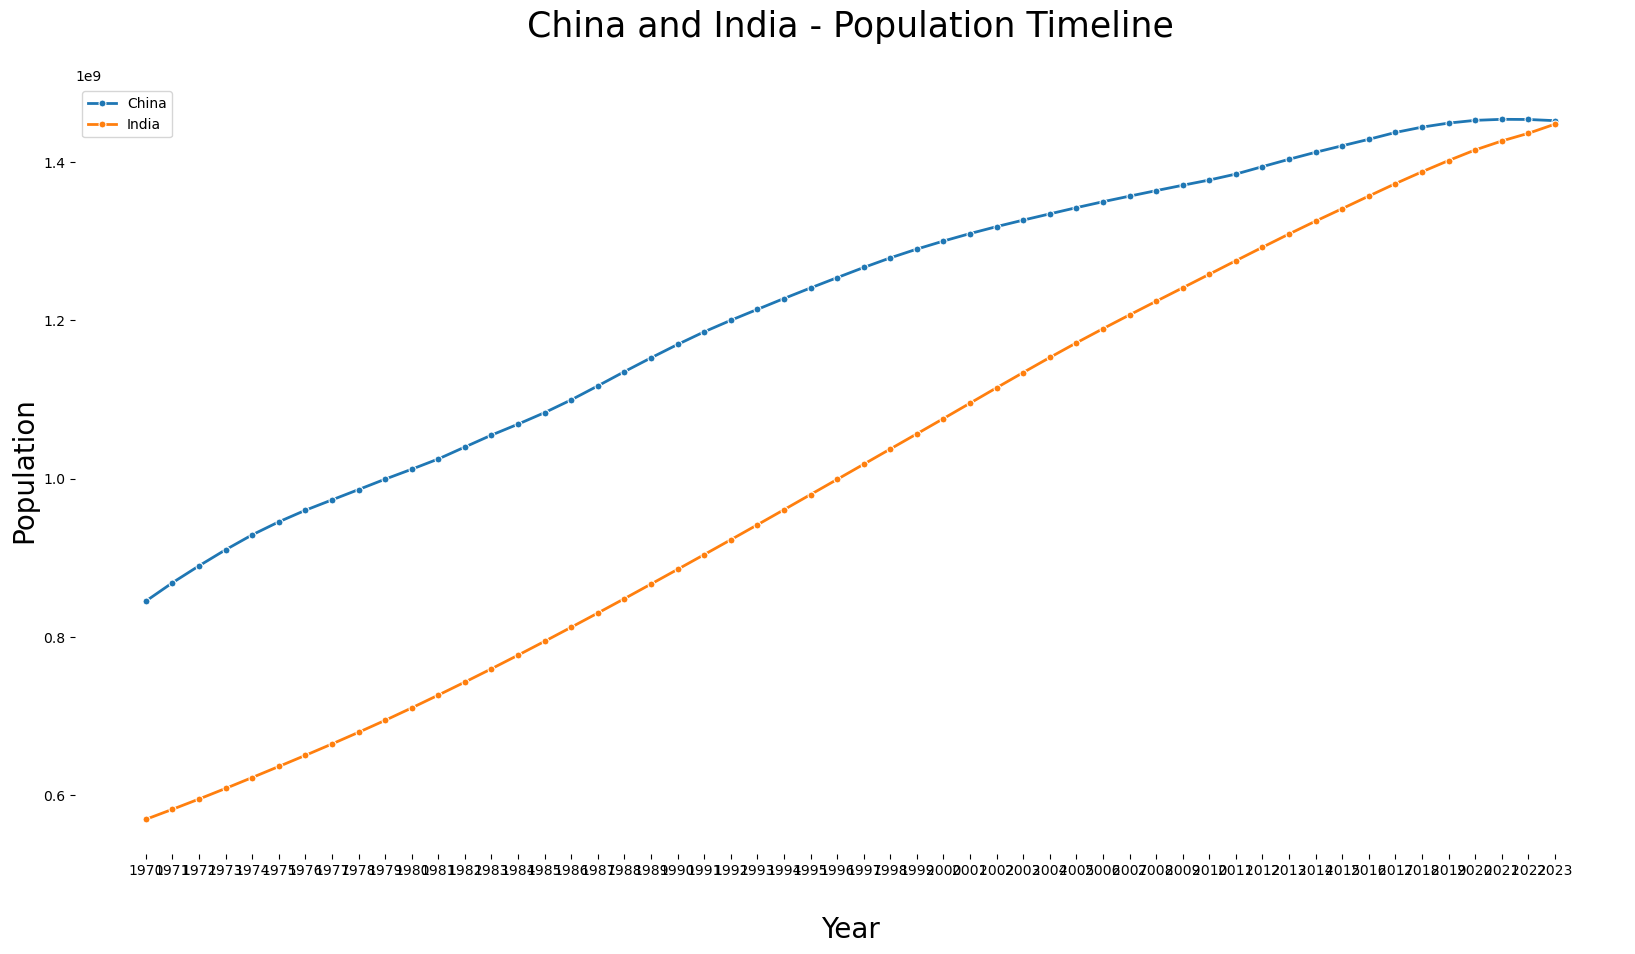

In [7]:
# Plotting the population of India and China for each year from 1970 to 2023

india_and_china = ['India','China']

plot_data = data[data["Country Name"].isin(india_and_china)].set_index("Country Name").drop(columns = ['Country Code','Continent','1970 Population'])

_, axs = plt.subplots(figsize=(20,10))

for col in plot_data.T.columns:
    sns.lineplot(x=plot_data.T.index ,y=plot_data.T[col].values,data=plot_data.T, ax=axs,marker="o",linewidth=2,markersize=5, label = col)

axs.set_title("China and India - Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

sns.despine(left=True, bottom=True)
plt.show()

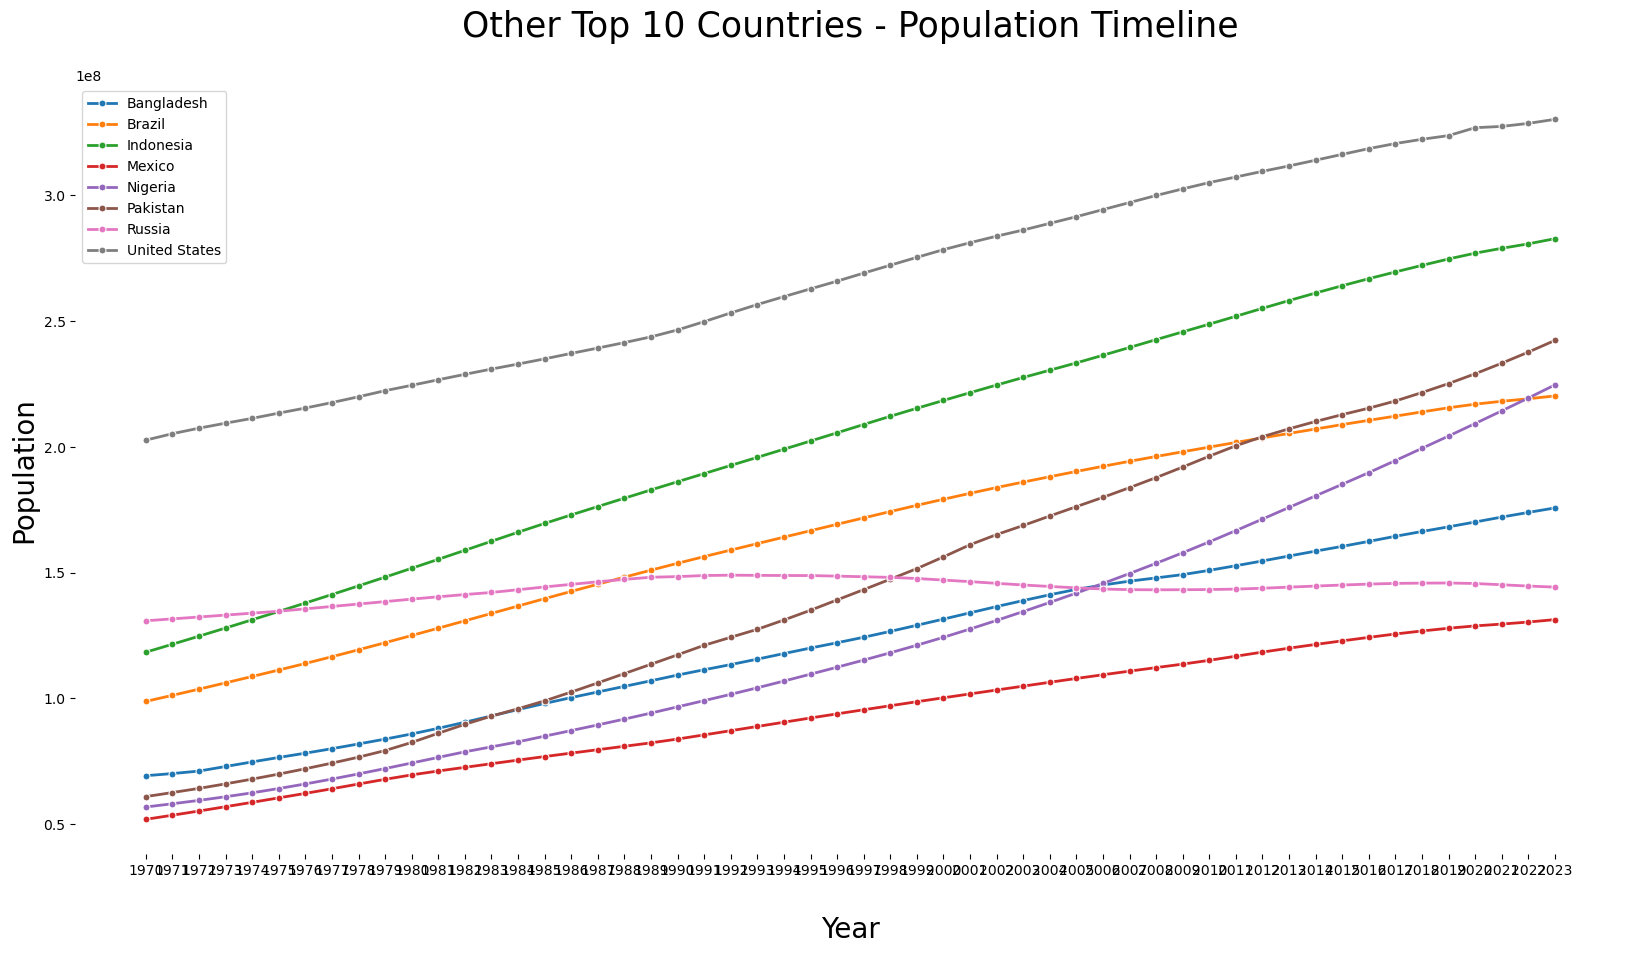

In [8]:
# Plotting the population for the rest of the top 10 countries

top_10_countries_excl_Ind_Chn = data[~data["Country Name"].isin(['India','China'])].sort_values(by = '2023', ascending = False).head(8)['Country Name']

plot_data_excl_Ind_Chn = data[data["Country Name"].isin(top_10_countries_excl_Ind_Chn)].set_index("Country Name").drop(columns = ['Country Code','Continent','1970 Population'])
#plot_data.T#['India']

_, axs = plt.subplots(figsize=(20,10))

for col in plot_data_excl_Ind_Chn.T.columns:
    sns.lineplot(x=plot_data_excl_Ind_Chn.T.index ,y=plot_data_excl_Ind_Chn.T[col].values,data=plot_data_excl_Ind_Chn.T, ax=axs,marker="o",linewidth=2,markersize=5, label = col)

axs.set_title("Other Top 10 Countries - Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

sns.despine(left=True, bottom=True)
plt.show()

##### As you can see, each country has different curve shapes, and are at a different stage of population growth. Countries like China, Brazil and Mexico are already seeing a decline in the population growth, as their graphs are strightening in the recent years. On the other hand, countries like Pakistan and Nigeria are seeing a high growth in their population even in the recent years.

##### I now calculate the total population of the world every year in a separate dataframe.

Text(0, 0.5, 'Population')

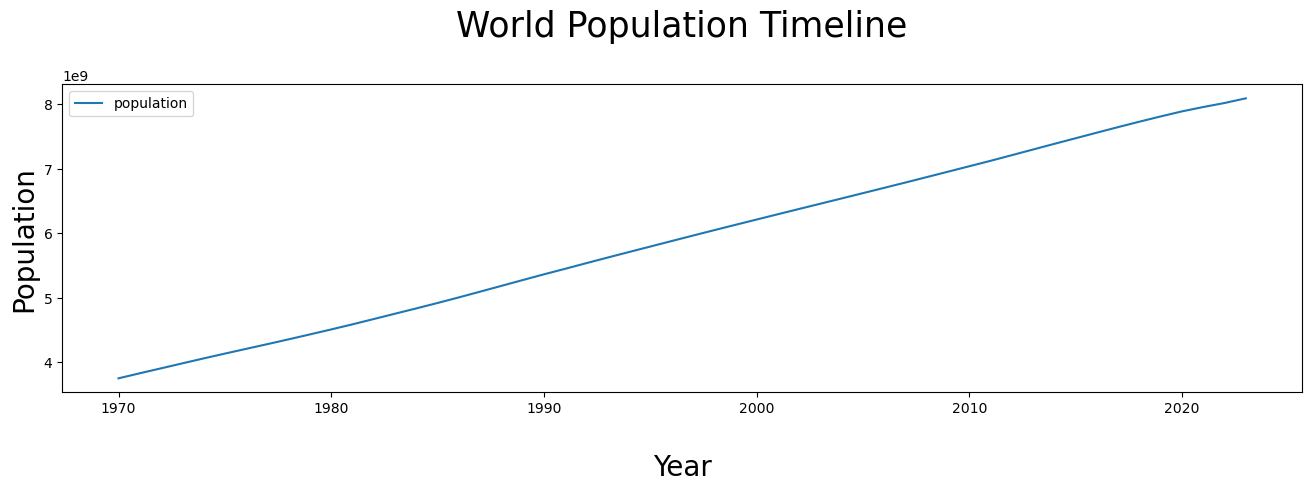

In [9]:
# Calculating the world population for each year from 1970 to 2023

world_data = pd.DataFrame(data.sum())
world_data = world_data[4:].rename(columns = {0: 'population'})

# Changing the year datatype to integer and re-setting it as index

world_data = world_data.reset_index()
world_data['index'] = world_data['index'].astype(int)
world_data = world_data.rename(columns = {'index': 'year'})
world_data = world_data.set_index('year')

# Plotting the world population over the years
axs = world_data.plot(figsize=(16,4))

axs.set_title("World Population Timeline\n",fontsize=25)
axs.set_xlabel("\nYear",fontsize=20)
axs.set_ylabel("Population",fontsize=20)

### Model 1: Degree 2 Feature Engineering Model on the entire world data

##### As you can see above, the world data has a steady upward trend, with no visible seasonal component. Hence, I decided not to use a Time series decomposition model and instead decided to focus mainly on the trend portion. Since my expectation is that the curve will have a gradually decreasing slope, I decided to use a second degree non-Linear Regression model (Feature engineering) as my baseline model. 

##### I set aside 20% of the data (years 2013 to 2023) as my test (dev) dataset, and used the rest of the data for the model training.

In [10]:
# Splitting the world data into training and dev sets

world_X = world_data.reset_index()[['year']]
world_y = world_data.reset_index()['population']

world_X_train = world_X.loc[:42, ['year']]
world_X_dev = world_X.loc[43:53, ['year']]

world_y_train = world_y.loc[:42]
world_y_dev = world_y.loc[43:53]

world_y_train.index = world_data.loc['1970':'2012'].index
world_y_dev.index = world_data.loc['2013':].index


##### Next, I built a pipeline with the first step to create the second degree polynomial features, followed by Linear Regression on these features. I fit this model on my training data and made predictions for my test dataset. Below, I have plotted the original world population data, along with the model's predictions for the test dataset in Red.

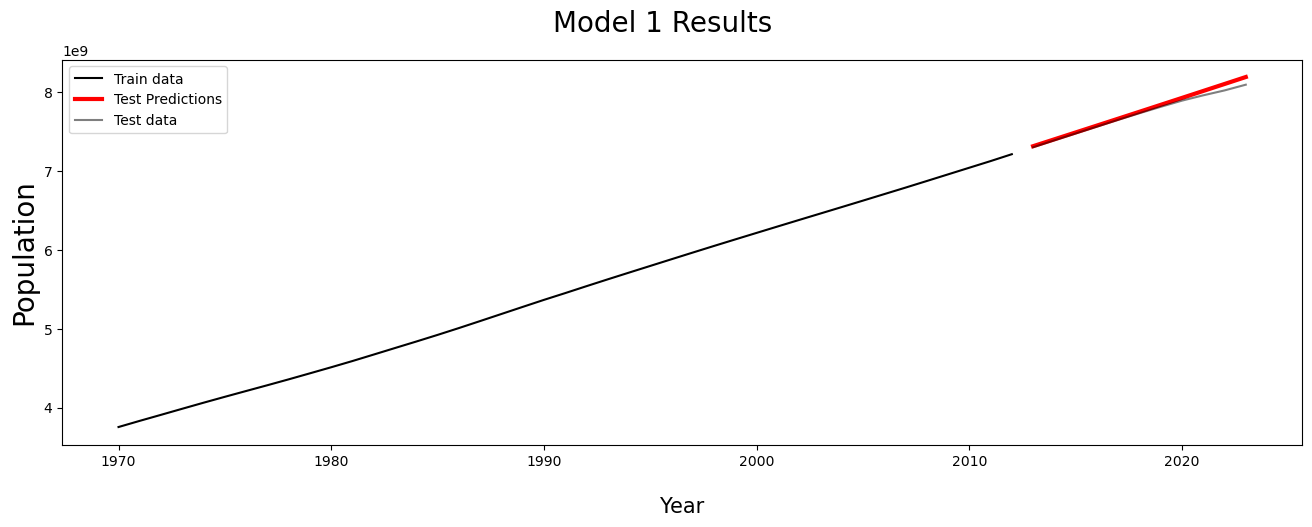

In [11]:
pipelined_model = Pipeline([
	('transform', PolynomialFeatures(degree = 2)),
	('regression', LinearRegression())   
])

pipelined_model.fit(world_X_train, world_y_train)
preds = pipelined_model.predict(world_X_dev)
results = pd.DataFrame({'year': world_y_dev.index, 'Prediction': preds}).set_index('year')
#pipelined_model.named_steps['regression'].coef_

plt.figure(figsize = (16,5))
plt.plot(world_y_train, 'k', label = 'Train data')
plt.plot(results, 'r', linewidth=3, label='Test Predictions')
plt.plot(world_y_dev, 'k', alpha=0.5, label = 'Test data')

plt.suptitle("Model 1 Results\n",fontsize=20)
plt.xlabel("\nYear",fontsize=15)
plt.ylabel("Population",fontsize=20)
plt.legend(loc='best')

In [12]:
mse_model1 = mean_squared_error(world_y_dev, results)

In [13]:
mse = mean_squared_error(world_y_dev, preds)
print("Model 1: Mean Squared Error = ", f'{mse:.2e}')

Model 1: Mean Squared Error =  2.02e+15


##### It was observed that the baseline model did not provide good results on the dev dataset. One strong reason for that is evident in the plots of country-level data. As we saw previously, each country has a different growth curve and is at a different stage in its growth trajectory. Hence, using a single second-degree regression model on the entire world dataset provides little insight. Instead, we should fit separate models for each country, predict the future populations for each of them, and then add them to get the world population predictions

### Model 2: Individual Best-fitting Feature Engineering Models for each country

##### For my second iteration, I used GridSearchCV to find the best-fitting nth degree polynomial feature model for each country, and then added the predictions to get the world population predictions.

##### I created a new DataFrame for the future dataset that contains the years 2024 thru 2080. This Dataframe will be used in our model to predict the future populations.

In [14]:
world_X_future = []

for i in range(2024, 2081):
    world_X_future.append({'year': i})
 
world_X_future = pd.DataFrame(world_X_future)

world_X_future.tail()

,year
52,2076
53,2077
54,2078
55,2079
56,2080


##### I iterate over each country, use GridSearchCV to find the best degree parameter for each country, and use that to predict the dev and future populations for the country. I then add them up to get the world population predictions

In [15]:
#Using GridSearchCV to get best models for each individual country and adding up the predictions

country_names = data['Country Name']
world_results = []
for country in country_names:
        
    country_data = data[data['Country Name'] == country]
    country_data = country_data.drop(columns = ['Country Name','Country Code','Continent','1970 Population']).T
    country_data = country_data.rename(columns = {country_names.eq(country).argmax(): 'population'})
    
    country_data = country_data.reset_index()
    country_data['index'] = country_data['index'].astype(int)
    country_data = country_data.rename(columns = {'index': 'year'})
    country_data = country_data.set_index('year')
    
    X = country_data.reset_index()[['year']]
    y = country_data.reset_index()['population']
    
    if y.isna().sum() > 0:
        continue
    
    X_train = X.loc[:42, ['year']]
    X_dev = X.loc[43:53, ['year']]
    
    y_train = y.loc[:42]
    y_dev = y.loc[43:53]

    params = {'transform__degree': [2,3,4]}
    
    pipelined_model = Pipeline([
    	('transform', PolynomialFeatures()),
    	('regression', LinearRegression())   
    ])

    model_finder = GridSearchCV(estimator = pipelined_model, param_grid = params, scoring = 'neg_mean_squared_error', cv = 5)

    model_finder.fit(X_train, y_train)
    best_model = model_finder.best_estimator_
    preds_dev = best_model.predict(X_dev)
    results_dev = pd.DataFrame({'year': X_dev.index, 'Prediction': preds_dev}).set_index('year')
    
    preds_future = best_model.predict(world_X_future)
    results_future = pd.DataFrame({'year': world_X_future['year'], 'Prediction': preds_future}).set_index('year')
    
    #pipelined_model.named_steps['regression'].coef_
    print(country, ": Degree: ", model_finder.best_params_)
    if country_names.eq(country).argmax() == 0:
        world_results_dev = results_dev
        world_results_future = results_future
    else:
        world_results_dev += results_dev
        world_results_future += results_future

world_results_dev.index = world_y_dev.index    

Afghanistan : Degree:  {'transform__degree': 2}
Albania : Degree:  {'transform__degree': 2}
Algeria : Degree:  {'transform__degree': 2}
American Samoa : Degree:  {'transform__degree': 3}
Andorra : Degree:  {'transform__degree': 4}
Angola : Degree:  {'transform__degree': 4}
Antigua and Barbuda : Degree:  {'transform__degree': 2}
Argentina : Degree:  {'transform__degree': 3}
Armenia : Degree:  {'transform__degree': 2}
Aruba : Degree:  {'transform__degree': 2}
Australia : Degree:  {'transform__degree': 2}
Austria : Degree:  {'transform__degree': 4}
Azerbaijan : Degree:  {'transform__degree': 2}
Bahamas : Degree:  {'transform__degree': 4}
Bahrain : Degree:  {'transform__degree': 4}
Bangladesh : Degree:  {'transform__degree': 3}
Barbados : Degree:  {'transform__degree': 3}
Belarus : Degree:  {'transform__degree': 2}
Belgium : Degree:  {'transform__degree': 4}
Belize : Degree:  {'transform__degree': 2}
Benin : Degree:  {'transform__degree': 2}
Bermuda : Degree:  {'transform__degree': 4}
Bhut

Model 2: Mean Squared Error =  5.94e+19


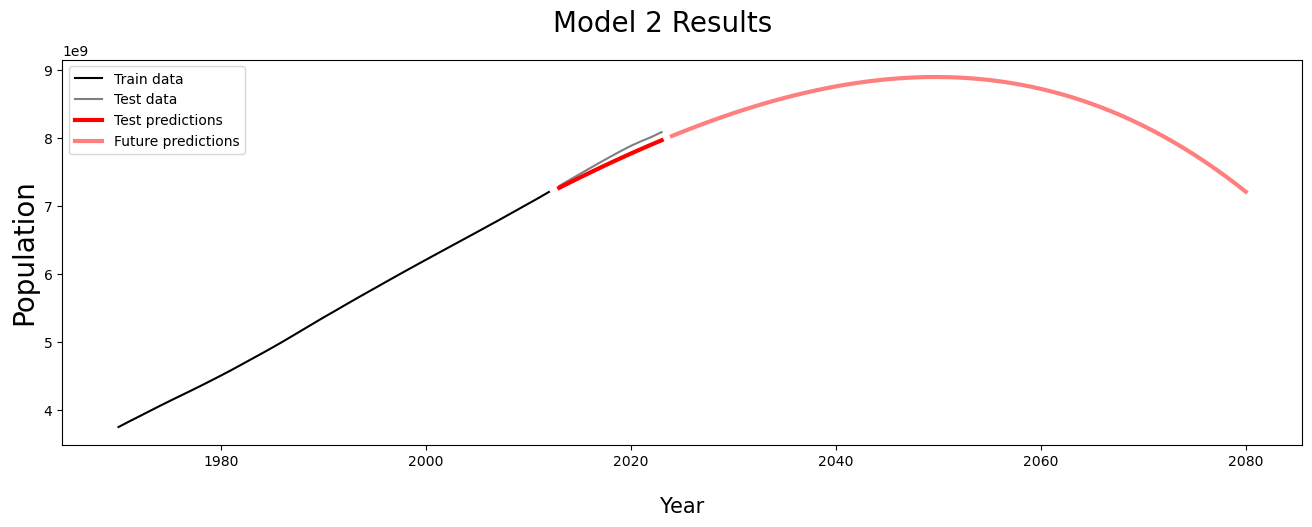

In [16]:
# Plotting the original data, dev and future predictions all on the same graph.

plt.figure(figsize = (16,5))
plt.plot(world_y_train, 'k', label = 'Train data')
plt.plot(world_y_dev, 'k', alpha=0.5, label = 'Test data')
plt.plot(world_results_dev, 'r', linewidth=3, label='Test predictions')
plt.plot(world_results_future, 'r', alpha = 0.5, linewidth=3, label='Future predictions')

plt.suptitle("Model 2 Results\n",fontsize=20)
plt.xlabel("\nYear",fontsize=15)
plt.ylabel("Population",fontsize=20)
plt.legend(loc='best')

mse_model2 = mean_squared_error(world_y_dev, results_dev)

print("Model 2: Mean Squared Error = ", f'{mse_model2:.2e}')

##### As you can see, this model did a better job of predicting the decline in population growth over time. We can now find out which year it predicts will be the year when the growth becomes zero, and what the maximum population will be. However, the mean squared error for this model got worse, and it predicted a steeper decline for the test data than what was in the actual test data.

In [17]:
maxima_year = 2024
for i in range(2025, 2081):
    if world_results_future.loc[i]['Prediction'] < world_results_future.loc[i - 1]['Prediction']:
        maxima_year = i
        break

print("Year of Max Population: ", i)
print("Max Population: " ,world_results_future.max()['Prediction'])

Year of Max Population:  2051
Max Population:  8903395552.523075


##### According to the Model 2 predictions, the world will reach its maximum population in 2051, and the population will be 8.903 billion. 

##### I will be covering more models in my final version of the project, along with the analysis of how the factors like Poverty, Hunger, food and water scarcity, infrastructure, etc. govern the population growth of a country. 

